Paquetes necesarios

In [52]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
from sklearn.ensemble import RandomForestClassifier
from collections import Counter

(938, 473, 3)


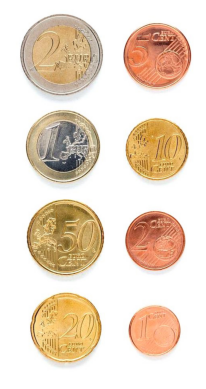

In [2]:
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
print(img.shape)
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.axis("off")
plt.imshow(img_rgb) 
plt.show()

Convierte a gris y muestra histograma

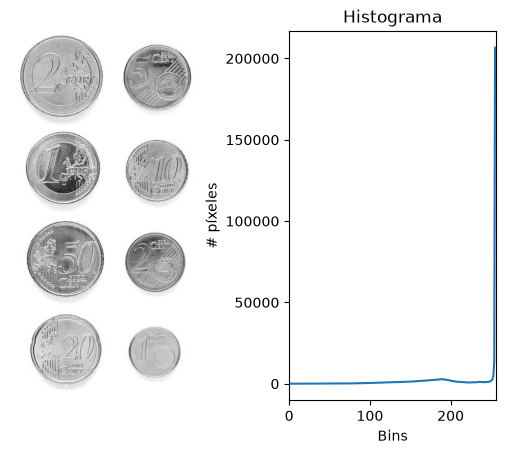

In [3]:
#Convierte la imagen a todos de gris, mostrando el resultado
img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#Cálculo del histograma con 256 bins de una imagen en escala de grises
hist = cv2.calcHist([img_gris], [0], None, [256], [0, 256])

plt.figure()
plt.subplot(1, 2, 1)
plt.axis("off")
plt.imshow(img_gris, cmap='gray')

# Histograma sin normalizar
plt.subplot(1, 2, 2)
plt.title("Histograma")
plt.xlabel("Bins")
plt.ylabel("# píxeles")
plt.plot(hist)
plt.xlim([0, 256])
# Separo subplots horizontalmente
plt.subplots_adjust(wspace=0.4)

Cuenta resultado tras umbralizar (poniendo a negro el fondo)

Umbral fijo usado  200.0
Umbral Otsu  204.0


Text(0.5, 1.0, 'OTSU invertida')

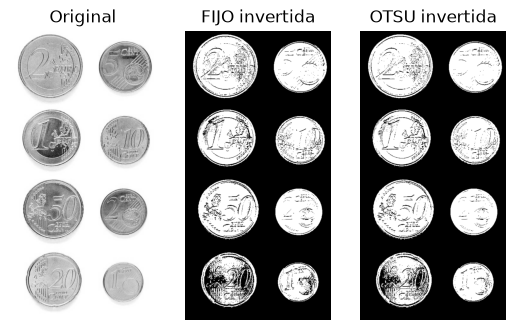

In [4]:
#Dos variantes de umbralizado. Probar otros parámetros, aplicar filtro previo, etc.
umbral = 200 # Prueba varios comenzando en 130
# Umbralizado binario invertido, dado que por defecto se asume objetos en blanco
th1,img_th1 = cv2.threshold(img_gris,umbral,255,cv2.THRESH_BINARY_INV)
print('Umbral fijo usado ', th1)
# Umbralizado con método de Otsu para selección automática del umbral
th2,img_th2 = cv2.threshold(img_gris,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral Otsu ', th2)

plt.subplot(1, 3, 1)
plt.axis("off")
plt.imshow(img_gris,cmap='gray') 
plt.title('Original')

plt.subplot(1, 3, 2)
plt.axis("off")
plt.imshow(img_th1,cmap='gray') 
plt.title('FIJO invertida')

plt.subplot(1, 3, 3)
plt.axis("off")
plt.imshow(img_th2,cmap='gray') 
plt.title('OTSU invertida')



Búsqueda de componentes y sus contornos

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


12740.0 600.4995620250702 ((366.5, 815.0), (126.0, 131.0), -90.0) 366.4169616699219 814.4717407226562 65.74198913574219 ((366.64166259765625, 814.06298828125), (125.09832000732422, 130.85784912109375), 86.78424072265625)
24682.5 643.7127649784088 ((141.0, 806.5), (175.0, 180.0), -90.0) 141.45033264160156 807.0255126953125 90.4556884765625 ((141.7595672607422, 807.3490600585938), (175.33294677734375, 179.72752380371094), 83.83692932128906)
17854.5 503.83051443099976 ((368.5, 587.0), (150.0, 151.0), -90.0) 368.2776184082031 586.7313842773438 76.19898986816406 ((368.3255615234375, 586.7984008789062), (150.0564727783203, 151.56260681152344), 91.99696350097656)
29172.5 675.1686074733734 ((140.35000610351562, 577.9500122070312), (191.31777954101562, 195.4287567138672), -71.56504821777344) 140.02484130859375 578.3192749023438 98.17779541015625 ((140.2999725341797, 577.9070434570312), (190.2574005126953, 195.45433044433594), 88.34276580810547)
19355.0 551.6711331605911 ((372.5, 355.0), (156.0,

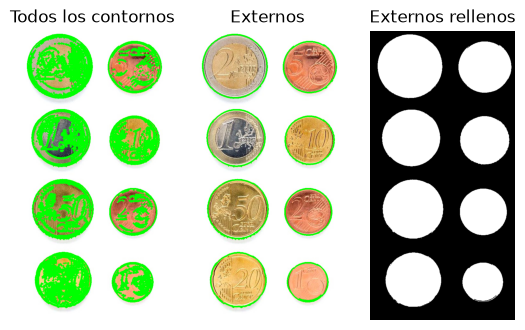

In [5]:
#Localiza contornos en imagen obtenida con umbral fijo
#findContours está diseñada para imágenes con  figura en blanco y fondo negro
#La imagen de entrada debe ser de un canal y 8 bits excepto en los modos RETR_CCOMP o RETR_FLOODFILL
#hierarchy contiene información sobre el nivel del contorno, relaciones paterno-filiales (contornos contenidos en otros)

#Obtiene todos los contornos: externos e internos
contornos, hierarchy = cv2.findContours(
    img_th1, #imagen
    cv2.RETR_TREE, #Modo de recuperación (lista, árbol, nivel superior)
    cv2.CHAIN_APPROX_SIMPLE #Método de aproximación del contorno
    )

#Dibuja sobre la imagen de entrada los contornos en verde
#Cada vez que quiere pintar convierte img para no tener restos
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos, -1, (0,255,0), 3)

plt.subplot(131)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Todos los contornos')

#Obtiene únicamente los contornos externos
contornos2, hierarchy2 = cv2.findContours(img_th1, 
    cv2.RETR_EXTERNAL , 
    cv2.CHAIN_APPROX_SIMPLE)

#Dibuja sobre la imagen de entrada sólo contornos externos
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos2, -1, (0,255,0), 3)

plt.subplot(132)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Externos')

#Dibuja contornos externos rellenos en imagen vacía
#Imagen negra
img_cont = np.zeros(img_rgb.shape)
#Recorre los contornos externos
for c in contornos2:
    #Área del contorno
    area = cv2.contourArea(c)
    #Área mínima (útil filtrar en ocasiones)
    if area > 10:
        #Perímetro del contorno
        perimetro = cv2.arcLength(c,True)
        #Contenedor alineado con ejes de la imagen
        x,y,w,h = cv2.boundingRect(c)
        #Mínimo contenedor ajustado para el contorno
        rect = cv2.minAreaRect(c)
        #Mínimo círculo que contiene al contorno
        (cx,cy),radio = cv2.minEnclosingCircle(c)
        #Elipse ajustada al contorno, exgigiendo un mínimo de puntos del contornos
        if c.shape[0] > 5:
            elipse = cv2.fitEllipse(c)
            #Para determinadas tareas nos puede interesará mostrar los valores obtenidos del contorno
            print(area, perimetro, rect, cx,cy,radio, elipse)

        #Dibuja los contornos
        cv2.drawContours(img_cont, [c], -1, (255,255,255), -1)

plt.subplot(133)
plt.axis("off")
plt.imshow(img_cont) 
plt.title('Externos rellenos')
plt.show()


Alternativa contando círculos utilizando la Transformada de Hough. La selección de parámetros puede ser "divertida", más [información](https://docs.opencv.org/4.x/da/d53/tutorial_py_houghcircles.html)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


[[[130.5 113.5 104.5]
  [140.5 579.5  91.1]
  [141.5 806.5  89.8]
  [127.5 346.5  87.3]
  [373.5 117.5  80.8]
  [370.5 353.5  77.4]
  [369.5 586.5  75.1]
  [366.5 815.5  65.7]]]


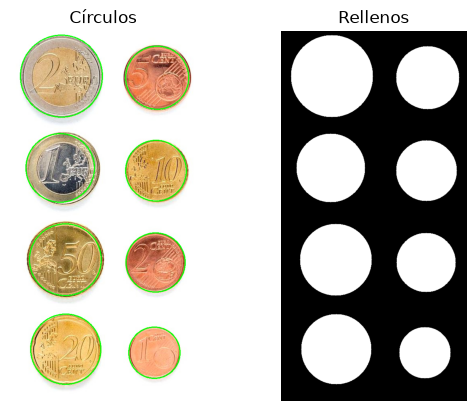

In [6]:
#Conversión a gris
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#Suaviza imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)
#Localiza Círculos
circ = cv2.HoughCircles(
        pimg,  # imagen 
        cv2.HOUGH_GRADIENT,  # tipo de detección
        1,
        100,  # distancia mínima entre círculos
        param1=100, # valor del gradiente
        param2=50, # umbral acumulador
        minRadius=50,  # radio mínimo
        maxRadius=150,  # radio máximo
    )

print(circ)

#Dibuja sobre entrada e imagen vacía
img_cont = np.zeros(img_rgb.shape)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
for det in circ[0]:
        x_coor, y_coor, det_radio = det
        cv2.circle(img_rgb,(int(x_coor), int(y_coor)),
            int(det_radio),(0, 255, 0), 2)
        cv2.circle(img_cont,(int(x_coor), int(y_coor)),
            int(det_radio),(255, 255, 255), -1)

#Muestra resultado
plt.subplot(121)
plt.axis("off")
plt.imshow(img_rgb) 
plt.title('Círculos')

plt.subplot(122)
plt.axis("off")
plt.imshow(img_cont) 
plt.title('Rellenos')

plt.show()

Las formas localizadas tienen distintas características geométricas, que pueden estimarse a partir de sus contornos. Más información en la [documentación de OpenCV](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html).

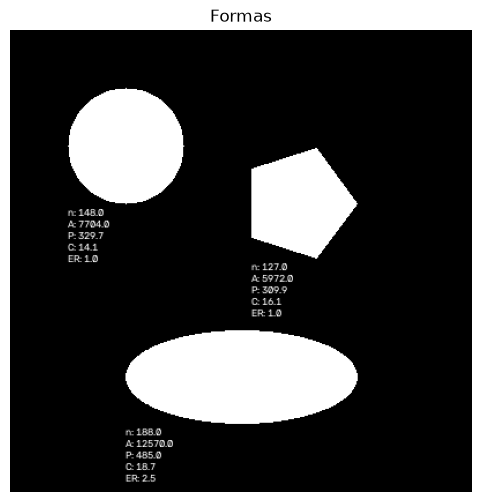

In [7]:
#Creación de polígono regular
def poligono_regular(image, ctr, radio, lados, color):
    pts = []
    ang_step = 2 * np.pi / lados
    for i in range(lados):
        ang = i * ang_step
        x = int(ctr[0] + radio * np.cos(ang))
        y = int(ctr[1] + radio * np.sin(ang))
        pts.append((x, y))
    pts = np.array(pts, np.int32)
    #regorganiza
    pts = pts.reshape((-1, 1, 2))
    cv2.fillPoly(image, [pts], color=color)

# Imagen vacía
img = np.zeros((400, 400, 1), dtype="uint8")
color = (255, 255, 255)

# Formas básicas
cv2.circle(img, (100, 100), 50, color, -1)  # Circular
poligono_regular(img, (250, 150), 50, 5, color)  # Polígono regular
cv2.ellipse(img, (200, 300), (100, 40), 0, 0, 360, color, -1)  # Elíptica

# Localiza contornos
contours, _ = cv2.findContours(img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Parámeros texto
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.3
thickness = 1

# Process each contour to calculate compactness and ellipse ratio (if possible)
for c in contours:
    # Puntos del contorno
    clon = len(c)

    # Área y perímetro
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)

    #Contenedor alineado con ejes de la imagen
    x,y,w,h = cv2.boundingRect(c)
    
    # Compactness: 4*pi*Area/Perimeter^2
    if perimetro > 0:
        compacidad = (perimetro ** 2) / area
    else:
        compactness = 0
    
    # Ajusta elipse si hay suficientes puntos
    if clon >= 5:
        elipse = cv2.fitEllipse(c)
        (center, axes, orientation) = elipse
        major_axis = max(axes)
        minor_axis = min(axes)
        elipse_ratio = major_axis / minor_axis
    else:
        elipse_ratio = None
    
    # Muestra valores en imageb
    cv2.putText(img, f"n: {clon:.1f}", (x, int(y+h+10)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img, f"A: {area:.1f}", (x, int(y+h+20)), font, font_scale, (255, 255, 255), thickness)
    cv2.putText(img, f"P: {perimetro:.1f}", (x, int(y+h+30)), font, font_scale, color, thickness)
    cv2.putText(img, f"C: {compacidad:.1f}", (x, int(y+h+40)), font, font_scale, color, thickness)
    cv2.putText(img, f"ER: {elipse_ratio:.1f}", (x, int(y+h+50)), font, font_scale, color, thickness)
    
# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Formas")
plt.axis('off')
plt.show()


TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [8]:
#Obtener primero la cantidad de dinero en la imagen ideal
# código para detección de los contornos exteriores

img = cv2.imread('Monedas.jpg') 
img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

umbral = 200 # Prueba varios comenzando en 130
# Umbralizado binario invertido, dado que por defecto se asume objetos en blanco
th1,img_th1 = cv2.threshold(img_gris,umbral,255,cv2.THRESH_BINARY_INV)

#diámetros de las monedas en mm de mayor a menor valor (https://www.carm.es/web/pagina?IDCONTENIDO=718&IDTIPO=100&RASTRO=c285$m)
monedas_diámetro_mm = [25.75,23.25,24.25,22.25,19.75,21.25,18.75,16.26]
monedas_valor = [2, 1, 0.5, 0.20, 0.10, 0.05, 0.02, 0.01]

#Obtiene únicamente los contornos externos
contornos_ideal, hierarchy_ideal = cv2.findContours(img_th1, 
    cv2.RETR_EXTERNAL , 
    cv2.CHAIN_APPROX_SIMPLE)

#Dibuja sobre la imagen de entrada sólo contornos externos
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img, contornos_ideal, -1, (0,255,0), 3)

escala = 0

# función para hacer clic en la imagen y detectar qué contorno
def seleccionar_moneda(evento, x, y, flags, param):
    global escala

    if evento == cv2.EVENT_LBUTTONDOWN:
        for i, contorno in enumerate(contornos_ideal):
            resultado = cv2.pointPolygonTest(contorno, (float(x), float(y)), False)

            if resultado >= 0:
                (_, _), radio = cv2.minEnclosingCircle(contornos_ideal[i])
                diametro_px = 2*radio

                escala = monedas_diámetro_mm[1] / diametro_px
                print(escala)

cv2.namedWindow("Imagen")
cv2.setMouseCallback("Imagen", seleccionar_moneda, img)


while True:
    cv2.imshow("Imagen", img)

    tecla = cv2.waitKey(1) & 0xFF

    if tecla == ord("q"):
        break

cv2.destroyAllWindows()

0.12346291421878539


In [9]:
monedas_diámetro_mm = [25.75,23.25,24.25,22.25,19.75,21.25,18.75,16.26]
monedas_valor = [2, 1, 0.5, 0.20, 0.10, 0.05, 0.02, 0.01]

def calcular_a_p(diametros):
    diametros = np.array(diametros)
    radios = diametros / 2
    areas = np.pi * np.square(radios)
    perimetros = np.pi * diametros

    relacion_a_p = areas / perimetros

    print(perimetros)
    print(areas)

    print(relacion_a_p)

    return relacion_a_p


relaciones = calcular_a_p(monedas_diámetro_mm)

[80.89601083 73.0420292  76.18362185 69.90043654 62.04645491 66.75884389
 58.90486225 51.08229655]
[520.76806972 424.5567947  461.86320746 388.82117827 306.35437111
 354.65635816 276.11654182 207.64953547]
[6.4375 5.8125 6.0625 5.5625 4.9375 5.3125 4.6875 4.065 ]


In [10]:
def contar_monedas(escala, contornos):
    total_value = 0

    for c in contornos:
        area = cv2.contourArea(c)

        if area > 10: 
            (_, _), radio_otra = cv2.minEnclosingCircle(c)

            diametro_otra_px = 2 * radio_otra
            diametro_round = round(diametro_otra_px * escala, 0)

            for i, diametro_real in enumerate(monedas_diámetro_mm):
                if diametro_round == round(diametro_real, 0):
                    valor = monedas_valor[i]
                    total_value += valor

                    print("Diámetro:", diametro_round, "mm")
                    print("Valor de la moneda:", valor, "€")
                    break
    return total_value

print(contar_monedas(escala, contornos_ideal))

Diámetro: 16.0 mm
Valor de la moneda: 0.01 €
Diámetro: 22.0 mm
Valor de la moneda: 0.2 €
Diámetro: 19.0 mm
Valor de la moneda: 0.02 €
Diámetro: 24.0 mm
Valor de la moneda: 0.5 €
Diámetro: 20.0 mm
Valor de la moneda: 0.1 €
Diámetro: 23.0 mm
Valor de la moneda: 1 €
Diámetro: 21.0 mm
Valor de la moneda: 0.05 €
Diámetro: 26.0 mm
Valor de la moneda: 2 €
3.88


In [11]:
vid = cv2.VideoCapture(0)

TOLERANCIA_MM = 0.8
RADIOS_MM = np.array(monedas_diámetro_mm) / 2

while True:
    ret, frame = vid.read()

    if ret:
        total_value = 0

        img_gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Suavizado (recomendado para HoughCircles)
        img_blur = cv2.GaussianBlur(img_gris, (9, 9), 2)

        # Detección de círculos con Hough
        circulos = cv2.HoughCircles(
            img_blur,                    # imagen en escala de grises
            cv2.HOUGH_GRADIENT,
            dp=1,
            minDist=15,                 # distancia mínima entre círculos
            param1=90,                  # umbral superior del Canny interno
            param2=35,                   # umbral del acumulador
            minRadius=10,
            maxRadius=85,
        )

        if circulos is not None:
            # Redondear a enteros
            circulos = np.round(circulos[0, :]).astype("int")
            circulos = sorted(circulos, key=lambda c: c[2], reverse=True)
            x_ref, y_ref, r_ref = circulos[0]
            escala_mm_por_px = RADIOS_MM[0] / r_ref


            for (x, y, radio) in circulos:
                cv2.circle(frame, (x, y), radio, (0, 255, 0), 3)
                radio_mm = radio * escala_mm_por_px
                idx = np.argmin(np.abs(RADIOS_MM - radio_mm))
                if abs(RADIOS_MM[idx] - radio_mm) < TOLERANCIA_MM:
                    total_value += monedas_valor[idx]
                    cv2.circle(frame, (x, y), radio, (255, 0, 0), 3)
                else:
                    cv2.circle(frame, (x, y), radio, (0, 0, 255), 3)  # no reconocida

            print(f"Valor total = {round(total_value, 2) - 2}")

        cv2.imshow('Resultado', frame)

    if cv2.waitKey(20) == 27:
        break

vid.release()
cv2.destroyAllWindows()

Valor total = 0


La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

Umbral escogido  197.0


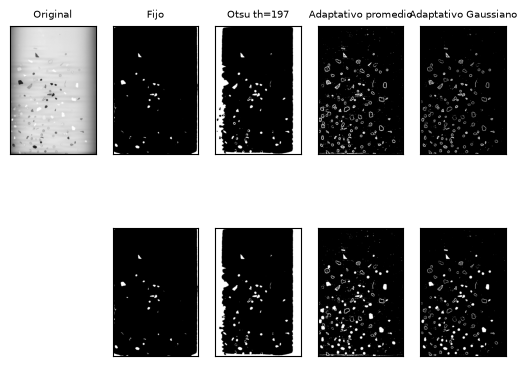

In [6]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth1 = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth1, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

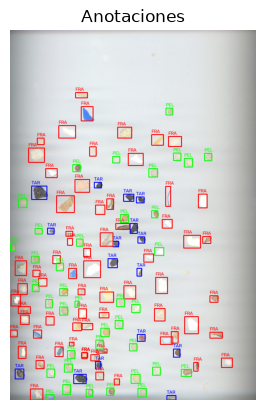

In [ ]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
            
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


##Muestras de entrenamiento

Text(0.5, 1.0, 'Alquitrán')

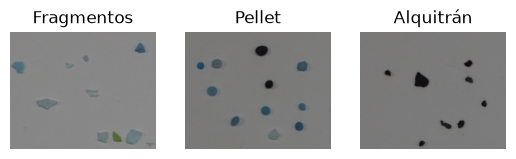

In [2]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('FRA.png') 
imgP = cv2.imread('PEL.png') 
imgT = cv2.imread('TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

Anotaciones  [0, 0, 0, 3, 3, 1, 0, 3, 3, 3, 1, 2, 2, 1, 3, 0, 2, 2, 3, 3, 1, 3, 2, 2, 0, 3, 1, 1, 1, 3, 3, 3, 2, 2, 3, 1, 3, 1, 1, 0, 2, 3, 1, 0, 0, 3, 0, 0, 2, 0, 0, 3, 1, 3, 1, 1, 3, 1, 2, 2, 3, 2, 3, 3, 0, 0, 2, 3, 2, 2, 1, 2, 2, 2, 1, 2, 0, 2, 2, 2, 1, 1, 1, 3, 2, 3, 3, 0, 1, 2, 3, 3, 3, 1, 2, 3, 0, 1, 2, 1]
Predicciones  [3, 0, 0, 1, 2, 1, 0, 0, 3, 2, 1, 3, 3, 3, 3, 0, 2, 3, 3, 0, 1, 1, 3, 3, 3, 0, 2, 3, 3, 1, 1, 1, 1, 1, 3, 2, 1, 0, 3, 1, 0, 0, 2, 2, 3, 3, 1, 0, 2, 3, 3, 1, 2, 2, 1, 1, 3, 1, 1, 1, 3, 1, 2, 2, 1, 3, 1, 0, 0, 3, 3, 0, 1, 1, 0, 0, 3, 3, 3, 1, 3, 0, 0, 3, 0, 1, 3, 0, 0, 0, 3, 0, 1, 0, 3, 2, 3, 2, 3, 2]
¿Cómo de bien encajan anotación y predicción?
Accuracy (TP/(n))= 0.24
Precision (TP/(TP+FP)) = 0.22550980392156858
Recall (TP/(TP+FN)) = 0.24
F1 Score (2*(precision*recall)/(precision+recall)) = 0.2289980607627666


Text(38.236490885416664, 0.5, 'Real/Anotado')

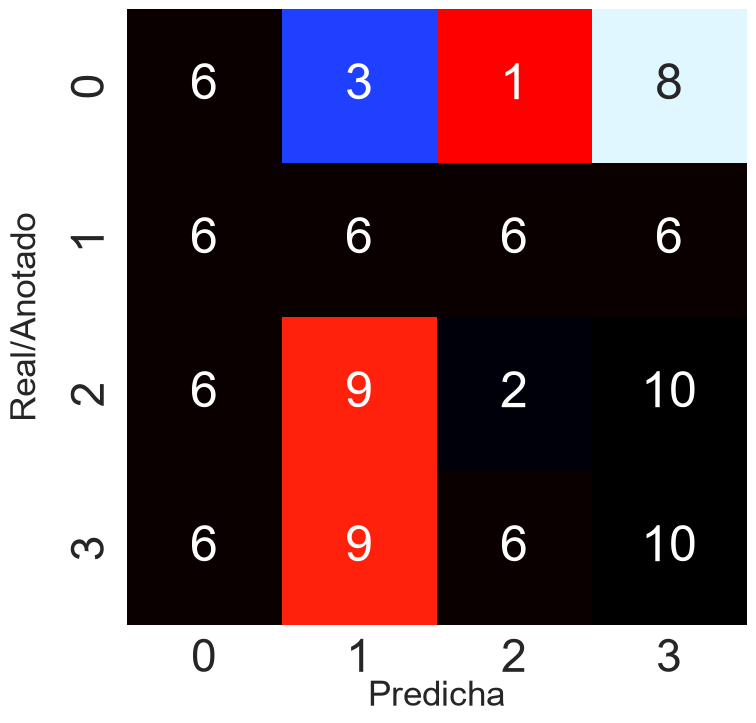

In [20]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [16]:
1. Segmentar las 3 imágenes de entrenamiento
    1.1 probar distintas técnicas de segmentado en cada imagen

2. Extracción de características (geométricas)
    2.1. aprender patrones de manera automática

3. Decidir crear nuestro clasificador o entrenar uno existente (con las tres imágenes de entrenamiento)

4. testear con la imagen de test

5. métricas con la matriz de confusión
    5.1. función para el cálculo de la matriz de confusión


SyntaxError: invalid syntax (3831523474.py, line 1)

In [97]:
#función para generar matriz de confusión y métricas
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def metrics(predictions, real_values):

    #Cálculo de métricas
    accuracy = accuracy_score(real_values, predictions)
    #Para más de una clase se define la forma de promediar
    precision = precision_score(real_values, predictions,average='weighted')
    recall = recall_score(real_values, predictions,average='weighted')
    f1score = f1_score(real_values, predictions,average='weighted')

    print(f"Accuracy (TP/(n))= {accuracy}")
    print(f"Precision (TP/(TP+FP)) = {precision}")
    print(f"Recall (TP/(TP+FN)) = {recall}")
    print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")

    conf_matrix = confusion_matrix(real_values, predictions)
    plt.figure(figsize=(8,8))
    sns.set(font_scale = 1.75)#tamaños tipografía
    sns.set(font_scale = 3.0)

    ax = sns.heatmap(
            conf_matrix, # confusion matrix 2D array 
            annot=True, # Muestra números en las celdas
            fmt='d', # valores enteros
            cbar=False, # sin barra de colores
            cmap='flag', # mapa de colores
            #vmax=175 # contraste de color
        )

    #Etiquetas matriz de confusión
    label_font = {'size':'25'}
    ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
    ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)
    


def csv_processing():
    csv_file = "MPs_test_bbs.csv"

    labels = []
    results = []

    labels_to_number = {"PEL" : 1, "FRA" : 0, "TAR" : 2}

    with open(csv_file, newline="") as file:
        reader = csv.DictReader(file)
        for row in reader:
            etiqueta = row["label"]
            labels.append(labels_to_number[etiqueta])

            x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])

            results.append((x_min, x_max, y_min, y_max))

    return (labels, results)

Text(0.5, 1.0, 'Alquitrán')

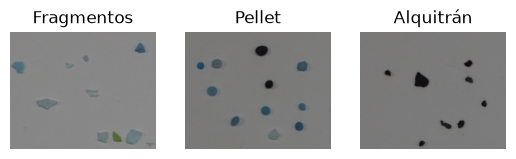

In [12]:
#carga de las tres imágenes
imgF = cv2.imread('FRA.png') 
imgP = cv2.imread('PEL.png') 
imgT = cv2.imread('TAR.png')

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

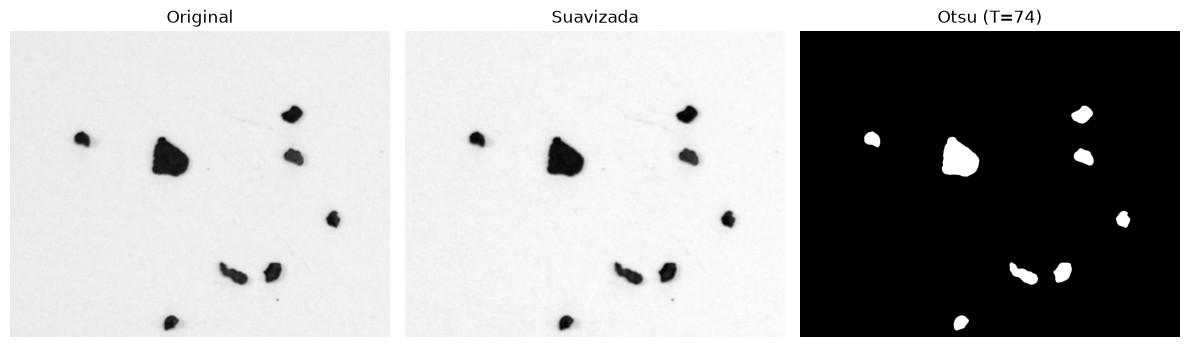

In [13]:
def blur_and_otsu(img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Suavizar la imagen para reducir el ruido
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)

    # Umbralización automática de Otsu
    umbral, otsu = cv2.threshold(
        suavizada,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(gris, cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(suavizada, cmap='gray')
    plt.title("Suavizada")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(otsu, cmap='gray')
    plt.title(f"Otsu (T={umbral:.0f})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return otsu

processedT = blur_and_otsu(imgT) # dejar el otsu

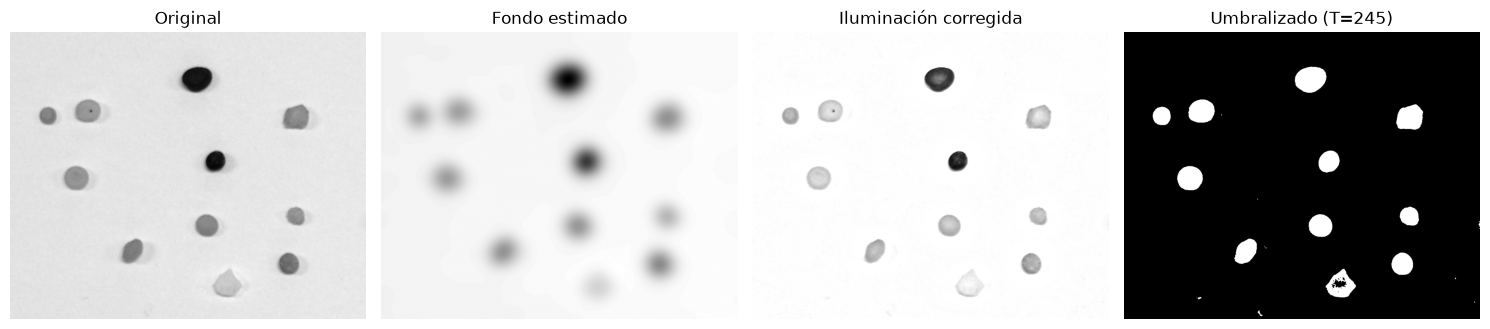

In [14]:
def blur_and_th_with_illumination_correction(img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Estimar el fondo y sus variaciones de iluminación
    fondo = cv2.GaussianBlur(gris, (0, 0), sigmaX=25)

    # 2. Corregir la iluminación
    corregida = cv2.divide(gris, fondo, scale=255)

    # 3. Suavizado ligero
    suavizada = cv2.GaussianBlur(corregida, (5, 5), 0)

    # 4. Umbralización automática de Otsu
    umbral, th = cv2.threshold(
        suavizada,
        245,
        255,
        cv2.THRESH_BINARY_INV
    )

    # Mostrar resultados
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(gris, cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(fondo, cmap='gray')
    plt.title("Fondo estimado")
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(corregida, cmap='gray')
    plt.title("Iluminación corregida")
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(th, cmap='gray')
    plt.title(f"Umbralizado (T={umbral:.0f})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return th

processedP = blur_and_th_with_illumination_correction(imgP)

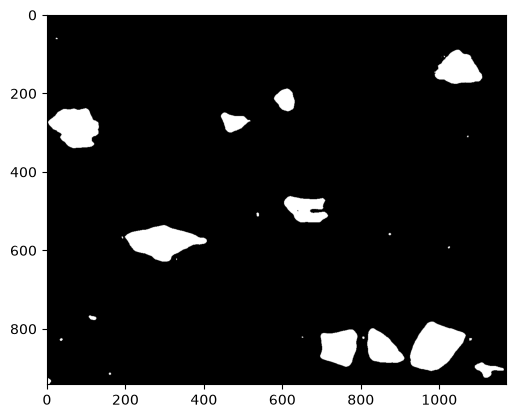

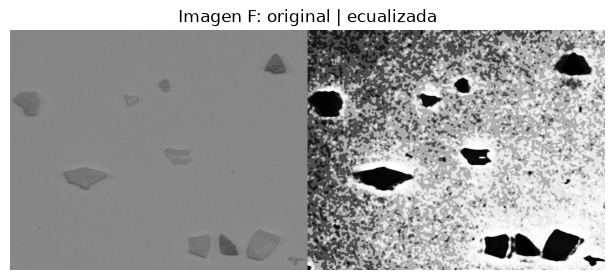

In [18]:
#Segmentación de las tres imágenes de entrenamiento

def histogram(img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    suavizada = cv2.medianBlur(gris, 9)
    hist = cv2.calcHist(
        [suavizada],    # Imagen de entrada
        [0],       # Canal que se analiza
        None,      # Sin máscara
        [256],     # Número de intervalos
        [0, 256]   # Rango de intensidades
    )

    return hist.flatten(), cv2.equalizeHist(suavizada)


def threshold_otsu(img):
    _, th = cv2.threshold(img,15,255,cv2.THRESH_BINARY_INV)
    plt.imshow(th, cmap='gray')
    return th 

hist, eq_hist1 = histogram(imgF)
hist3, eq_hist3 = histogram(imgP)

processedF = threshold_otsu(eq_hist1) #dejar así


#---------------------------------------------------------------------------

res = np.hstack((cv2.cvtColor(imgF, cv2.COLOR_BGR2GRAY), eq_hist1))
#res3 = np.hstack((cv2.cvtColor(imgP, cv2.COLOR_BGR2GRAY), eq_hist3))

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.imshow(res, cmap='gray')
plt.title("Imagen F: original | ecualizada")
plt.axis('off')

plt.tight_layout()
plt.show()

Matriz FINAL = [[ 1258.           193.19595814    29.66985552     2.00517132
    121.           120.            99.        ]
 [ 6813.           339.62236428    16.92989143     1.07375792
    122.           122.           110.        ]
 [ 5278.           303.07820785    17.40363776     1.71865313
     53.           102.            80.        ]
 [11498.           434.41630054    16.41307377     1.36753249
    124.           123.           102.        ]
 [10810.5          505.34523368    23.62275614     2.31525211
    123.           119.           108.        ]
 [ 4986.           386.39191699    29.94358474     1.52330637
    129.           131.           117.        ]
 [ 2155.5          205.23758864    19.54185469     1.46137761
    126.           127.           111.        ]
 [ 9045.5          405.88938987    18.21305586     1.26984589
    118.           101.            73.        ]
 [ 2067.5          176.40916169    15.05208819     1.21953611
    135.           128.           109.     

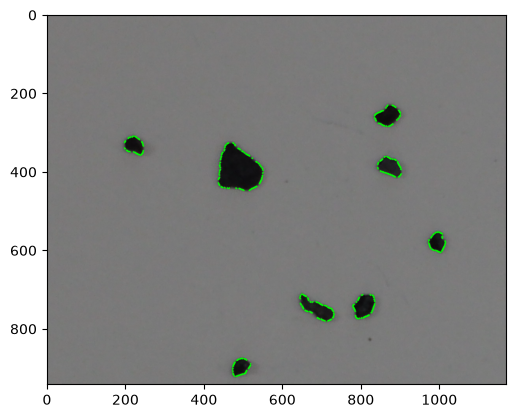

In [40]:
def extract_characteristics(proccessed_image, original_image, area_filter, clon_filter):
    contours, _ = cv2.findContours(proccessed_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    features_matrix = []
    coords = []

    for c in contours:
        area = cv2.contourArea(c)
        clon = len(c)

        if area >= area_filter and clon >= clon_filter:
            
            perimetro = cv2.arcLength(c, True)

            cv2.drawContours(original_image, c, -1, [0, 255, 0], 3)
            
            # compacidad
            if perimetro > 0:
                compacidad = (perimetro ** 2) / area
            else:
                compacidad = 0
            
            # ajuste elipse
            if clon >= 10:
                elipse = cv2.fitEllipse(c)
                (center, axes, orientation) = elipse
                major_axis = max(axes)
                minor_axis = min(axes)
                elipse_ratio = major_axis / minor_axis if minor_axis > 0 else 0
            else:
                elipse_ratio = 0 

            # hallar el centro del objeto para determinar su color
            M = cv2.moments(c)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
            else:
                x, y, w, h = cv2.boundingRect(c)
                cx = x + w // 2
                cy = y + h // 2

            b, g, r = original_image[cy, cx]

            coords.append((cy, cx))
            
            features_matrix.append([area, perimetro, compacidad, elipse_ratio, r, g, b])

    plt.imshow(original_image)
    return np.array(features_matrix), coords


np.set_printoptions(suppress=True)

matrixF, _ = extract_characteristics(processedF,imgF, 20, 40)
# prints para ver características extraídas y datos relacionados
# print(f"Matriz de FRAGMENTOS: {matrixF}")
#print(f"Características de la matriz: Ancho={len(matrixF[0])}, Alto={len(matrixF)}")


matrixP, _ = extract_characteristics(processedP,imgP, 20, 40)
# prints para ver características extraídas y datos relacionados
# print(f"Matriz de PELLET: {matrixP}")
#print(f"Características de la matriz: Ancho={len(matrixP[0])}, Alto={len(matrixP)}")


matrixT, _ = extract_characteristics(processedT,imgT, 20, 40)
# prints para ver características extraídas y datos relacionados
# print(f"Matriz de ALQUITRÁN: {matrixT}")
#print(f"Características de la matriz: Ancho={len(matrixT[0])}, Alto={len(matrixT)}")

# matriz de entrenamiento
final_matrix = np.vstack((matrixF, matrixP, matrixT))

y_F = np.full(len(matrixF), 0) 
y_P = np.full(len(matrixP), 1) 
y_T = np.full(len(matrixT), 2) 

# etiquetas
labels = np.concatenate((y_F, y_P, y_T))

print(f"Matriz FINAL = {final_matrix}")
print(f"ETIQUETAS {labels}")

In [24]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)

# entrenamos el clasificador con los datos obtenidos
clf.fit(final_matrix, labels)

csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

La clase de verdad es: 0
FALLO
La clase de verdad es: 2
ACIERTO
La clase de verdad es: 0
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 0
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 0
FALLO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 0
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 2
FALLO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 2
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 1
FALLO
La clase de verdad es: 0
FALLO
La clase de verdad es: 2
FALLO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 0
FALLO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 0
FALLO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 0
ACIERTO
La clase de verdad es: 1
FALLO
La clase de verdad es: 

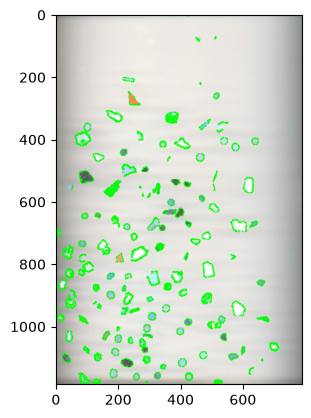

In [ ]:
# cargamos y procesamos la imagen de test
img_test = cv2.imread('MPs_test.jpg') 
img_test_grey = cv2.cvtColor(img_test, cv2.COLOR_BGR2GRAY)

processed_test = 255 - cv2.adaptiveThreshold(img_test_grey,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)

res,imth = cv2.threshold(processed_test,120,255,cv2.THRESH_BINARY)

matrix, coords = extract_characteristics(imth, img_test, 7, 11) # valores de "umbral" basados en prueba y error para obtener la mayor cantidad de muestras de la imagen
labels, results = csv_processing()

y_pred = []
y = []

for i in range(len(matrix)):

    cy, cx = coords[i]
    obj_characteristics = matrix[i]

    # extracción de la etiqueta del csv
    real_class = 0

    # hallamos la clase del objeto en cuestión
    for j in range(len(results)):
        x_min, x_max, y_min, y_max = results[j]
        # si su centro está contenido dentro del "bounding rectangle", asignamos esa clase y rompemos el bucle
        if x_min <= cx <= x_max and y_min <= cy <= y_max:
            real_class = labels[j]
            break

    # predicción con el clasificador
    obj_characteristics = matrix[i].reshape(1, -1)
    prediction = clf.predict(obj_characteristics)[0]

    # comparación de resultados
    if prediction == real_class:
        print("ACIERTO")
    else:
        print("FALLO")


================ RESUMEN GLOBAL ================
Total objetos evaluados: 133
Accuracy global: 0.436
Distribución y_real: Counter({0: 78, 1: 38, 2: 17})
Distribución y_pred: Counter({0: 98, 2: 34, 1: 1})
Matriz de confusión [filas=real, cols=pred]:
[[54  0 24]
 [32  0  6]
 [12  1  4]]
Accuracy (TP/(n))= 0.43609022556390975
Precision (TP/(TP+FP)) = 0.33819241982507287
Recall (TP/(TP+FN)) = 0.43609022556390975
F1 Score (2*(precision*recall)/(precision+recall)) = 0.3799270904534062


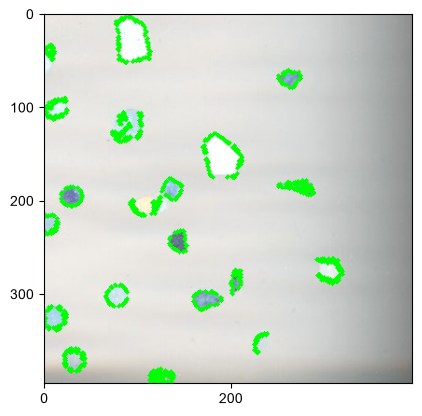

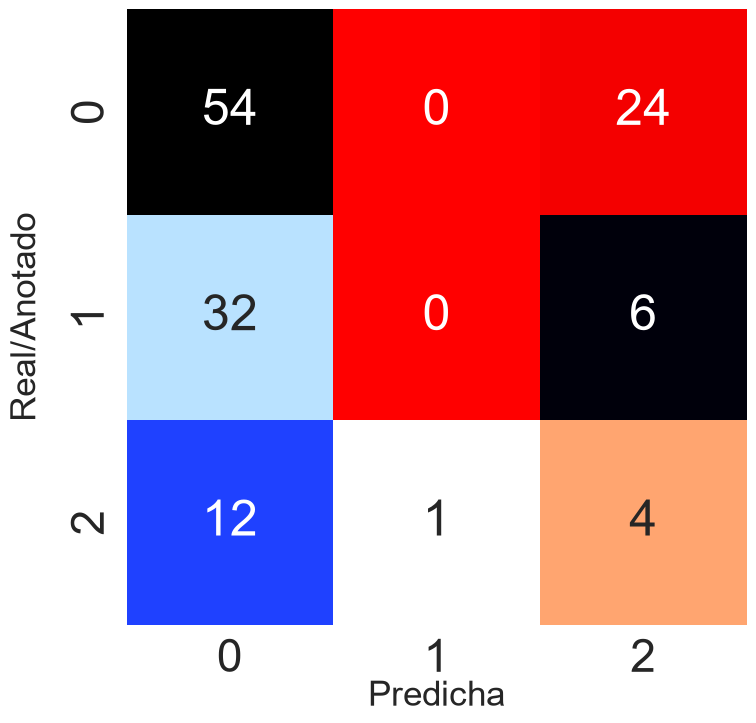

In [98]:
def preprocesar(grey_img, block_size=11, C=2, thr=120):
    processed = 255 - cv2.adaptiveThreshold(
        grey_img, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        block_size, C
    )
    _, imth = cv2.threshold(processed, thr, 255, cv2.THRESH_BINARY)
    return imth

def trocear_imagen(img, n_cols=2, n_rows=3):
    h, w = img.shape[:2]
    w_step = w // n_cols
    h_step = h // n_rows

    trozos = []
    for r in range(n_rows):
        for c in range(n_cols):
            x0 = c * w_step
            y0 = r * h_step
            # el último trozo de cada fila/columna absorbe el resto
            x1 = (c + 1) * w_step if c < n_cols - 1 else w
            y1 = (r + 1) * h_step if r < n_rows - 1 else h
            sub = img[y0:y1, x0:x1].copy()
            nombre = f"fila{r}_col{c}"
            trozos.append((nombre, sub, x0, y0))
    return trozos


def evaluar_subimagen(clf, sub_bgr, x0, y0, csv_labels, csv_results,
                      area_filter=20, clon_filter=40,
                      block_size=11, C=2, thr=120, verbose=False):
    # preprocesar el trozo
    grey = cv2.cvtColor(sub_bgr, cv2.COLOR_BGR2GRAY)
    imth = preprocesar(grey, block_size, C, thr)

    matrix, coords_locales = extract_characteristics(
        imth, sub_bgr.copy(), area_filter, clon_filter
    )

    if len(matrix) == 0:
        return {"nombre": None, "n": 0, "acc": None,
                "y_real": [], "y_pred": [], "matrix": matrix}

    y_real, y_pred = [], []

    for i in range(len(matrix)):
        cy_l, cx_l = coords_locales[i]
        cy_g = cy_l + y0
        cx_g = cx_l + x0

        real_class = 0
        for j, (x_min, x_max, y_min, y_max) in enumerate(csv_results):
            if x_min <= cx_g <= x_max and y_min <= cy_g <= y_max:
                real_class = csv_labels[j]
                break

        # predicción
        pred = int(clf.predict(matrix[i].reshape(1, -1))[0])

        y_real.append(real_class)
        y_pred.append(pred)

        if verbose == True:
            print(f"    objeto {i:3d}  global=({cy_g},{cx_g})  "
                  f"real={real_class}  pred={pred}  "
                  f"{'ACIERTO' if pred == real_class else 'FALLO'}")

    acc = accuracy_score(y_real, y_pred) if y_real else None
    return {"nombre": None, "n": len(matrix), "acc": acc,
            "y_real": y_real, "y_pred": y_pred, "matrix": matrix}

def evaluar_imagen_completa(clf, ruta_img, csv_labels, csv_results,
                            n_cols=2, n_rows=3,
                            area_filter=20, clon_filter=40,
                            block_size=11, C=2, thr=120,
                            verbose=False):
    img = cv2.imread(ruta_img)
    if img is None:
        raise FileNotFoundError(ruta_img)

    trozos = trocear_imagen(img, n_cols, n_rows)

    resultados_por_trozo = []
    y_real_all, y_pred_all = [], []

    for nombre, sub, x0, y0 in trozos:
        if verbose:
            print(f"\n=== Subimagen {nombre}  offset=({x0},{y0})  "
                  f"shape={sub.shape} ===")

        res = evaluar_subimagen(
            clf, sub, x0, y0, csv_labels, csv_results,
            area_filter=area_filter, clon_filter=clon_filter,
            block_size=block_size, C=C, thr=thr, verbose=False
        )
        res["nombre"] = nombre
        res["offset"] = (x0, y0)
        resultados_por_trozo.append(res)

        y_real_all.extend(res["y_real"])
        y_pred_all.extend(res["y_pred"])

        if verbose == True:
            if res["acc"] is None:
                print(f"  -> sin objetos en este trozo")
            else:
                print(f"  -> n={res['n']}  acc={res['acc']:.3f}")

    # resumen global
    print("\n================ RESUMEN GLOBAL ================")
    print(f"Total objetos evaluados: {len(y_real_all)}")
    if y_real_all:
        print(f"Accuracy global: {accuracy_score(y_real_all, y_pred_all):.3f}")
        print(f"Distribución y_real: {Counter(y_real_all)}")
        print(f"Distribución y_pred: {Counter(y_pred_all)}")
        print("Matriz de confusión [filas=real, cols=pred]:")
        print(confusion_matrix(y_real_all, y_pred_all))
    else:
        print("No se ha detectado ningún objeto. Revisa filtros/preprocesado.")

    return resultados_por_trozo, y_real_all, y_pred_all


test_labels, test_results = csv_processing()

# 3) evaluar la imagen completa troceada
res_trozos, y_real_all, y_pred_all = evaluar_imagen_completa(
    clf, "MPs_test.jpg", test_labels, test_results,
    n_cols=2, n_rows=3,
    area_filter=30, clon_filter=20,   
    block_size=11, C=2, thr=120,
    verbose=False
)

metrics(y_pred_all, y_real_all)
